# Proyecto Bitcoin Sabana Agent RL: Ejecución y Resultados

Este notebook ejecuta el pipeline del proyecto y reúne los artefactos principales para el informe: preparación de datos, chequeo de lookahead, análisis exploratorio, entrenamiento, evaluación, tablas y gráficas.
La recompensa se selecciona con validación. El conjunto de test es held-out y no debe consultarse para ajustar el modelo. Su ejecución está desactivada inicialmente.

## 1. Preparación y opciones de ejecución

In [17]:
from pathlib import Path
import os
import sys
import subprocess
import importlib.util

ROOT = next((path for path in (Path.cwd(), *Path.cwd().parents)
             if (path / 'configs' / 'default.yaml').is_file() and (path / 'src').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('No encuentro la raíz del proyecto (configs/default.yaml). Abre el notebook desde el repositorio.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

required_modules = ['numpy', 'pandas', 'matplotlib', 'yaml', 'torch', 'gymnasium']
missing_modules = [name for name in required_modules if importlib.util.find_spec(name) is None]
if missing_modules:
    raise ModuleNotFoundError(f'Faltan dependencias: {missing_modules}. Usa Python 3.10-3.12, ejecuta `%pip install -e .` desde la raíz y reinicia el kernel.')

print(f'Raíz del proyecto: {ROOT}')
print(f'Python: {sys.executable}')
print('Dependencias principales disponibles.')

Raíz del proyecto: c:\Users\PaolaEspinosaHurtado\OneDrive - Lexsoft Systems, S.L\Personal\Unisabana\Simulacion\Proyecto final\Bitcoin_Sabana_Agent_RL
Python: c:\Users\PaolaEspinosaHurtado\AppData\Local\Programs\Python\Python313\python.exe
Dependencias principales disponibles.


In [18]:
# Cambia RUN_TRAINING a False solo si ya existen los checkpoints que quieres evaluar.
RUN_TRAINING = False
# El test es held-out: cambia a True únicamente después de cerrar la decisión usando validación.
RUN_HELD_OUT_TEST = True

CONFIG_PATH = 'configs/default.yaml'
RESULTS_DIR = ROOT / 'results'
RESULTS_DIR.mkdir(exist_ok=True)
print(f'Reentrenar todas las recompensas y semillas: {RUN_TRAINING}')
print(f'Ejecutar evaluación held-out: {RUN_HELD_OUT_TEST}')

Reentrenar todas las recompensas y semillas: False
Ejecutar evaluación held-out: True


## 2. Datos, particiones y control de lookahead
Si el archivo de mercado no existe, se descarga con el módulo oficial del proyecto. Las particiones y la normalización se construyen usando la configuración versionada.

In [19]:
import pandas as pd
import yaml
from src.data import load_config, load_prices, prepare, check_no_lookahead

cfg = load_config(CONFIG_PATH)
data_path = ROOT / cfg['data']['path']
if not data_path.exists():
    if importlib.util.find_spec('gym_trading_env') is None:
        raise ModuleNotFoundError(
            'No hay un dataset local y falta gym-trading-env, requerido solo para descargar datos. '
            'Usa Python 3.10-3.12, ejecuta `%pip install -e .` desde la raíz y reinicia el kernel.'
        )
    print(f'No existe {data_path.relative_to(ROOT)}; descargando datos...')
    subprocess.run([sys.executable, '-m', 'src.data'], cwd=ROOT, check=True)
else:
    print(f'Usando datos existentes: {data_path.relative_to(ROOT)}')

raw = load_prices(str(data_path))
check_no_lookahead(raw, cfg)
splits = prepare(cfg)
split_rows = []
for split_name, split_df in splits.items():
    split_rows.append({'particion': split_name, 'inicio': split_df.index.min(),
                       'fin': split_df.index.max(), 'velas': len(split_df)})
split_table = pd.DataFrame(split_rows).set_index('particion')
display(split_table)

Usando datos existentes: data\binance-BTCUSDT-1h.pkl
Lookahead check passed (5 random cut points).


,inicio,fin,velas
particion,,,
train,2019-01-08 05:00:00,2023-12-31 23:00:00,43591
val,2024-01-01 00:00:00,2024-12-31 23:00:00,8784
test,2025-01-01 00:00:00,2026-10-17 05:00:00,15702


## 3. Análisis exploratorio
Las gráficas siguientes usan únicamente entrenamiento y validación; no inspeccionan el período held-out.

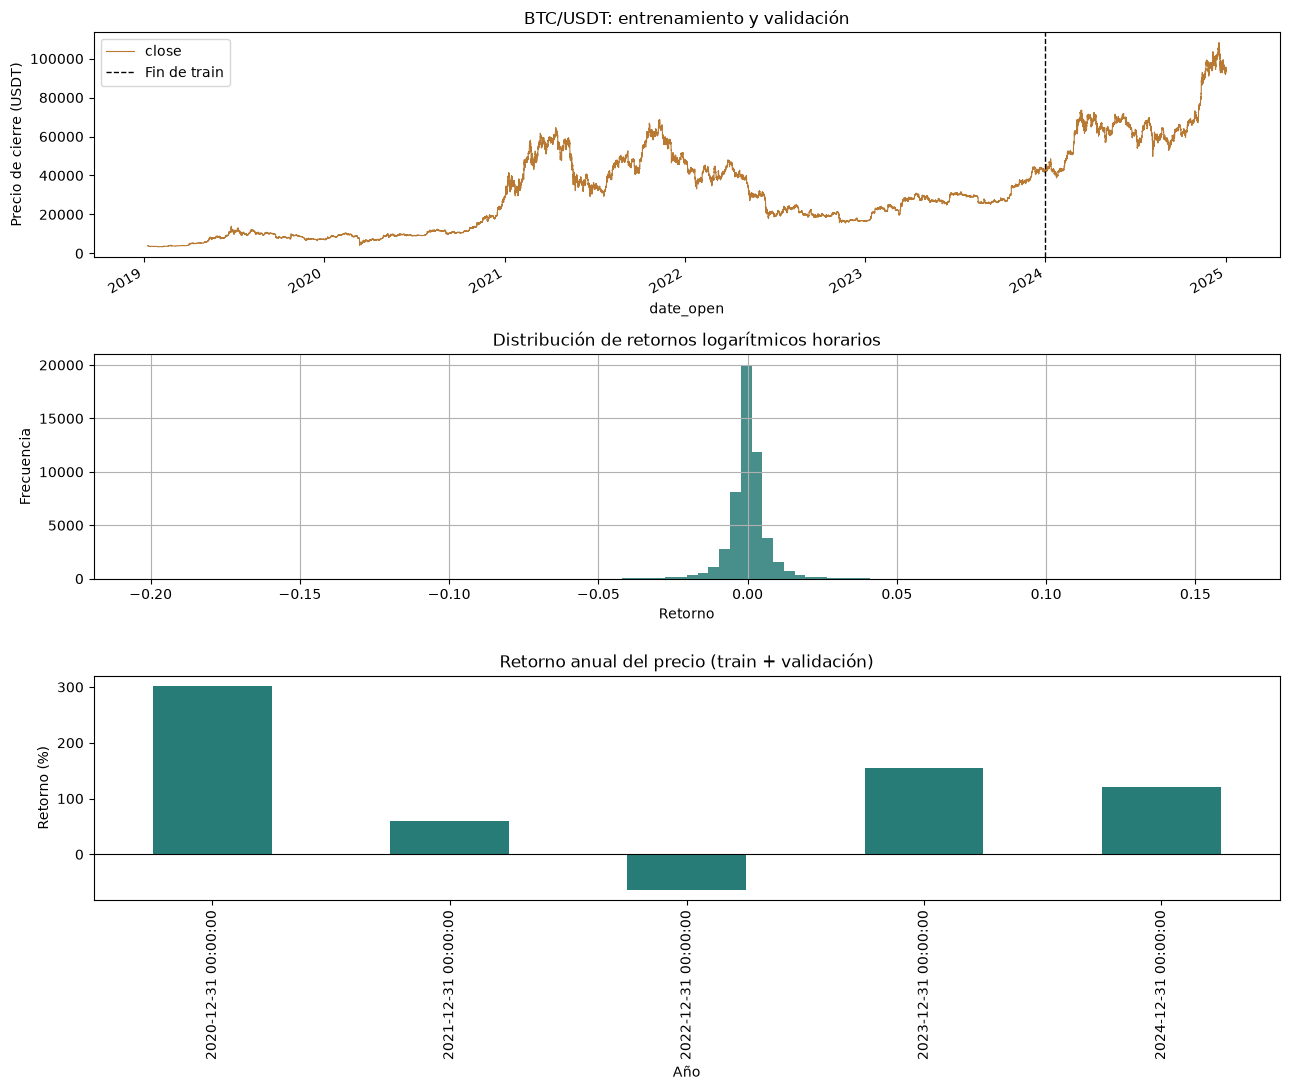

Retorno horario medio: 0.000060
Desviación estándar horaria: 0.007051
Asimetría: -0.83; curtosis en exceso: 48.42


In [20]:
import matplotlib.pyplot as plt
import numpy as np

train_val = pd.concat([splits['train'], splits['val']])
hourly_returns = np.log(train_val['close']).diff().dropna()
annual_returns = train_val['close'].resample('YE').last().pct_change().dropna()

fig, axes = plt.subplots(3, 1, figsize=(13, 11))
train_val['close'].plot(ax=axes[0], color='#b87932', lw=0.8)
axes[0].set(title='BTC/USDT: entrenamiento y validación', ylabel='Precio de cierre (USDT)')
axes[0].axvline(pd.Timestamp(cfg['data']['train_end']), color='black', ls='--', lw=1, label='Fin de train')
axes[0].legend()
hourly_returns.hist(ax=axes[1], bins=100, color='#287c78', alpha=0.85)
axes[1].set(title='Distribución de retornos logarítmicos horarios', xlabel='Retorno', ylabel='Frecuencia')
annual_returns.mul(100).plot(kind='bar', ax=axes[2], color='#287c78')
axes[2].axhline(0, color='black', lw=0.8)
axes[2].set(title='Retorno anual del precio (train + validación)', ylabel='Retorno (%)', xlabel='Año')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'eda_informe.png', dpi=140, bbox_inches='tight')
plt.show()

print(f'Retorno horario medio: {hourly_returns.mean():.6f}')
print(f'Desviación estándar horaria: {hourly_returns.std():.6f}')
print(f'Asimetría: {hourly_returns.skew():.2f}; curtosis en exceso: {hourly_returns.kurtosis():.2f}')

## 4. Entrenamiento
El comando usa las recompensas y semillas de `configs/default.yaml`. Cada checkpoint se selecciona por su desempeño en validación, nunca por test.

In [21]:
if RUN_TRAINING:
    subprocess.run([sys.executable, '-m', 'src.train', '--config', CONFIG_PATH], cwd=ROOT, check=True)
else:
    print('Entrenamiento omitido. Se reutilizarán los checkpoints existentes.')

expected_models = [ROOT / 'models' / f"{reward}_seed{seed}" / 'best_model.pt'
                   for reward in cfg['rewards'] for seed in cfg['seeds']]
missing_models = [str(path.relative_to(ROOT)) for path in expected_models if not path.exists()]
if missing_models:
    raise FileNotFoundError('Faltan checkpoints. Ejecuta el entrenamiento antes de evaluar: ' + ', '.join(missing_models))
print(f'Checkpoints disponibles: {len(expected_models)}')

Entrenamiento omitido. Se reutilizarán los checkpoints existentes.
Checkpoints disponibles: 12


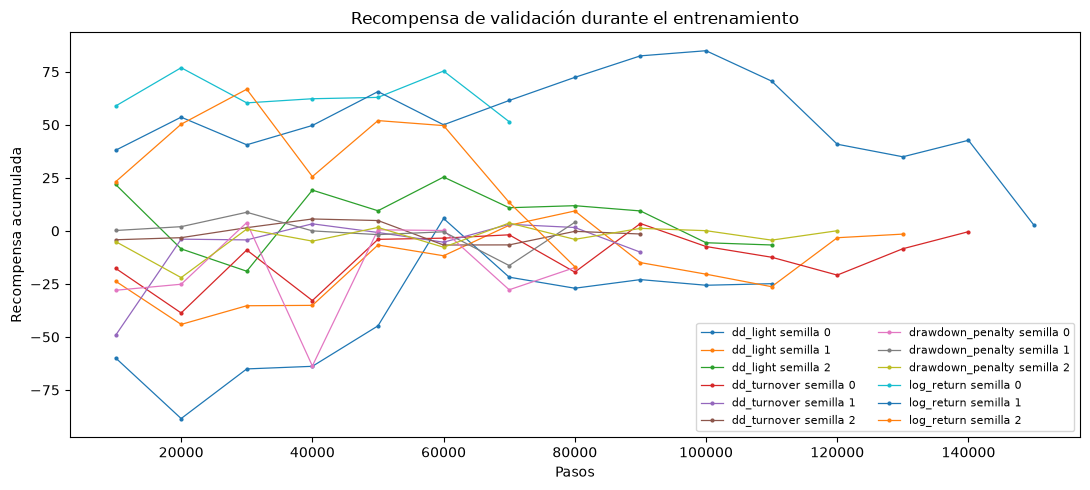

Curvas de entrenamiento leídas: 12


In [22]:
from IPython.display import display

curve_files = sorted((ROOT / 'models').glob('*_seed*/val_curve.csv'))
if curve_files:
    fig, ax = plt.subplots(figsize=(11, 5))
    for curve_file in curve_files:
        curve = pd.read_csv(curve_file)
        if not curve.empty:
            label = curve_file.parent.name.replace('_seed', ' semilla ')
            ax.plot(curve['step'], curve['val_reward'], marker='o', ms=2, lw=0.9, label=label)
    ax.set(title='Recompensa de validación durante el entrenamiento', xlabel='Pasos', ylabel='Recompensa acumulada')
    ax.legend(ncol=2, fontsize=8)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / 'curvas_entrenamiento.png', dpi=140, bbox_inches='tight')
    plt.show()
    print(f'Curvas de entrenamiento leídas: {len(curve_files)}')
else:
    print('Aún no hay archivos val_curve.csv.')

## 5. Evaluación y selección en validación
Esta comparación incluye todas las recompensas configuradas, baselines y semillas. Revisa el promedio por recompensa y fija `final_reward` en `configs/default.yaml` antes de habilitar el test.

,cum_return_%,max_drawdown_%,sharpe,return_over_dd,costs_$,n_trades,avg_exposure_%
Buy & hold,120.09,-32.31,1.76,3.72,100.00,1.00,100.00
RL log_return s0,115.79,-32.38,1.73,3.58,2858.32,36.00,99.62
RL dd_light ensemble,16.27,-13.43,0.83,1.21,2057.46,29.00,9.94
RL log_return s1,133.79,-14.49,2.63,9.23,27378.24,291.00,39.28
RL log_return s2,94.97,-27.23,1.70,3.49,34252.52,450.00,85.46
RL drawdown_penalty s0,7.33,-1.24,1.48,5.93,411.26,6.00,0.08
RL drawdown_penalty s1,10.83,-0.31,2.04,35.01,834.70,16.00,0.07
RL drawdown_penalty s2,17.47,-2.94,1.92,5.93,1456.64,14.00,0.23
RL dd_turnover s0,6.41,-0.88,1.29,7.32,1639.85,17.00,0.10
RL dd_turnover s1,7.75,-2.94,1.05,2.63,207.83,3.00,0.21


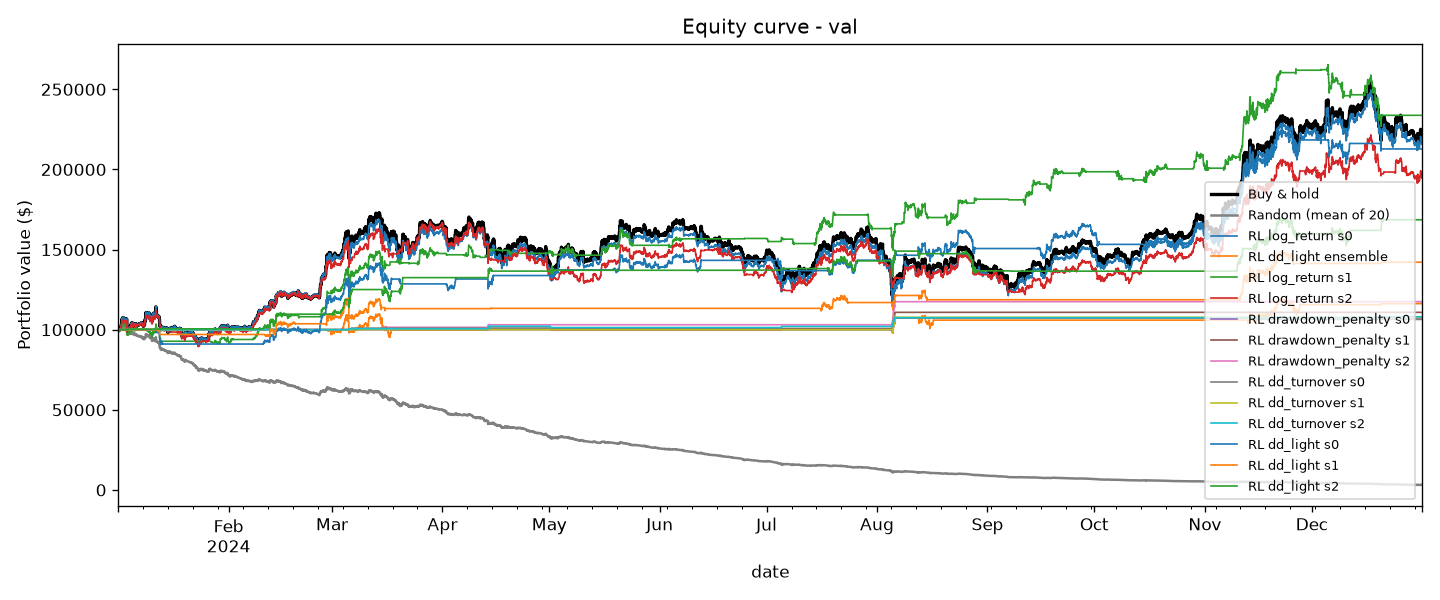

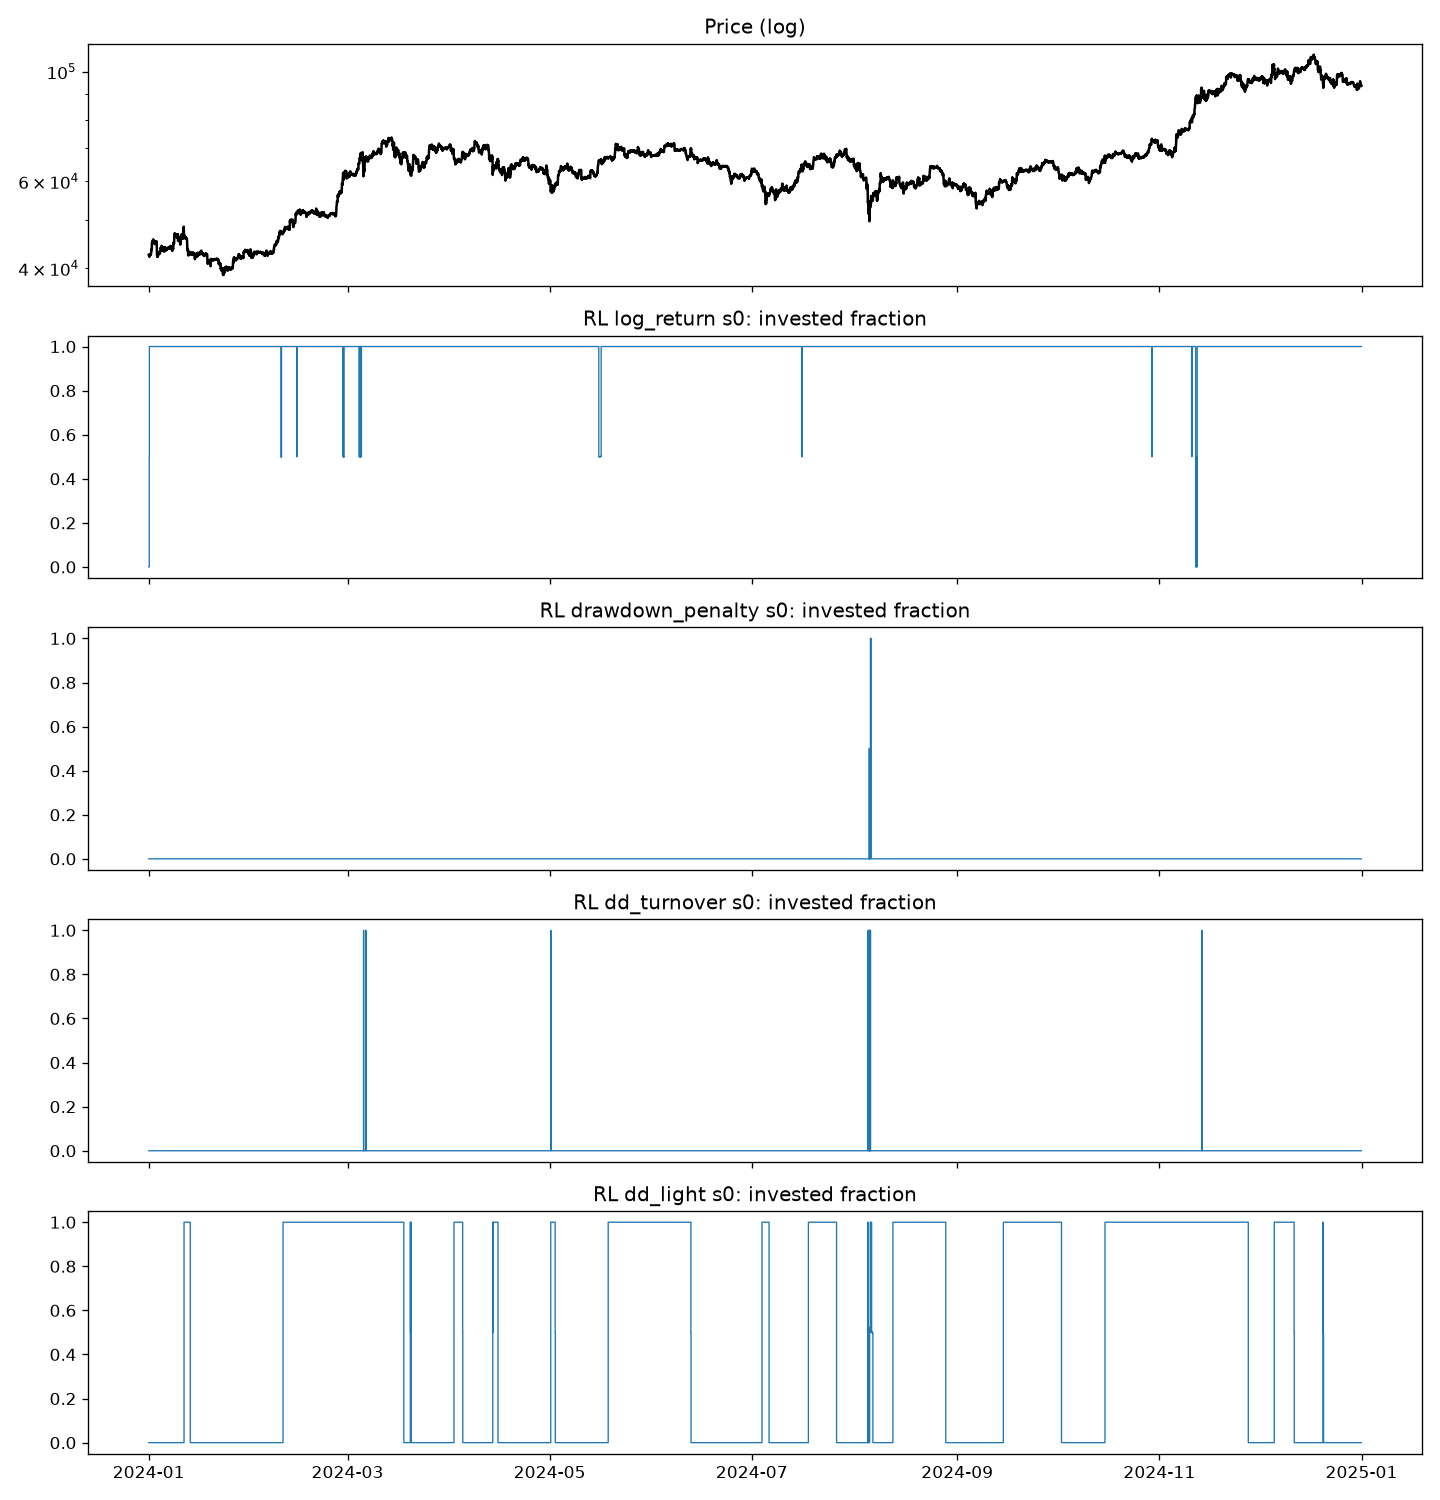

In [23]:
subprocess.run([sys.executable, '-m', 'src.evaluate', '--config', CONFIG_PATH, '--split', 'val'], cwd=ROOT, check=True)
metrics_val = pd.read_csv(RESULTS_DIR / 'metrics_val.csv', index_col=0)
display(metrics_val)

for image_name in ['equity_val.png', 'positions_val.png']:
    image_path = RESULTS_DIR / image_name
    if image_path.exists():
        display(__import__('IPython').display.Image(filename=str(image_path)))

### Decisión antes de test

Usa exclusivamente `metrics_val.csv` y las curvas/posiciones de validación para justificar la recompensa final. Edita `final_reward` en `configs/default.yaml` si la decisión difiere de la configuración actual. No elijas la semilla con mejor resultado como resultado principal: reporta el promedio de semillas.

La celda de test está protegida por `RUN_HELD_OUT_TEST = False`. Cambia esa opción a `True` únicamente cuando la decisión esté cerrada y el informe de validación esté completo.

In [24]:
cfg = load_config(CONFIG_PATH)
print(f"Recompensa final configurada: {cfg['final_reward']}")
print(f"Semillas: {cfg['seeds']}")
if cfg['final_reward'] not in cfg['rewards']:
    raise ValueError('final_reward debe coincidir con una recompensa declarada en cfg["rewards"].')
print('Antes del test, confirma que esta elección fue fijada usando únicamente validación.')

Recompensa final configurada: dd_light
Semillas: [0, 1, 2]
Antes del test, confirma que esta elección fue fijada usando únicamente validación.


## 6. Evaluación held-out y benchmark descriptivo
Al habilitar el test, se evalúa únicamente `final_reward`. El benchmark de exposición fija del proyecto se ejecuta después y no participa en la selección del modelo.

,cum_return_%,max_drawdown_%,sharpe,return_over_dd,costs_$,n_trades,avg_exposure_%
Buy & hold,-13.61,-53.74,0.03,-0.25,100.00,1.0,100.00
RL dd_light s0,68.72,-20.59,1.11,3.34,3046.63,45.0,57.49
RL dd_light ensemble,1.12,-14.14,0.12,0.08,1979.76,31.0,10.71
RL dd_light s1,5.16,-6.27,0.42,0.82,1265.67,21.0,1.35
RL dd_light s2,11.38,-16.21,0.44,0.70,3806.28,54.0,15.73
Random (mean of 20),-99.91,-99.91,-13.69,-1.00,102399.32,10466.9,50.08
RL dd_light (mean of seeds),28.42,-14.36,0.65,1.62,2706.19,40.0,24.85


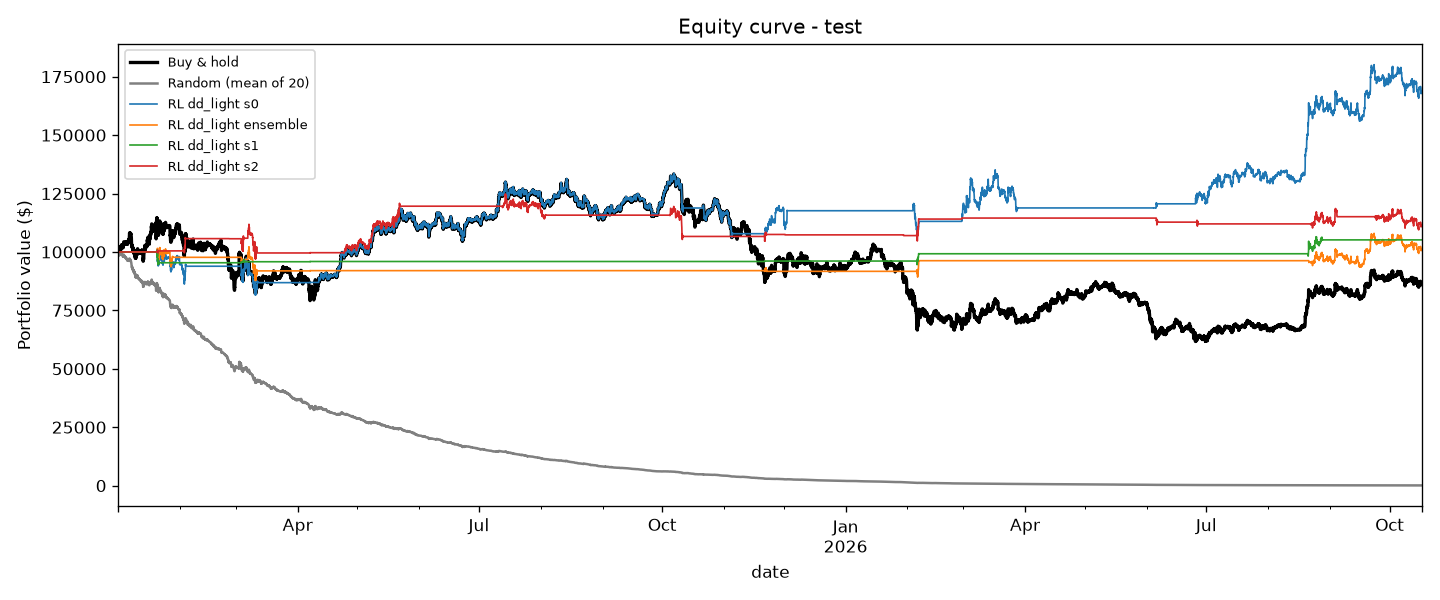

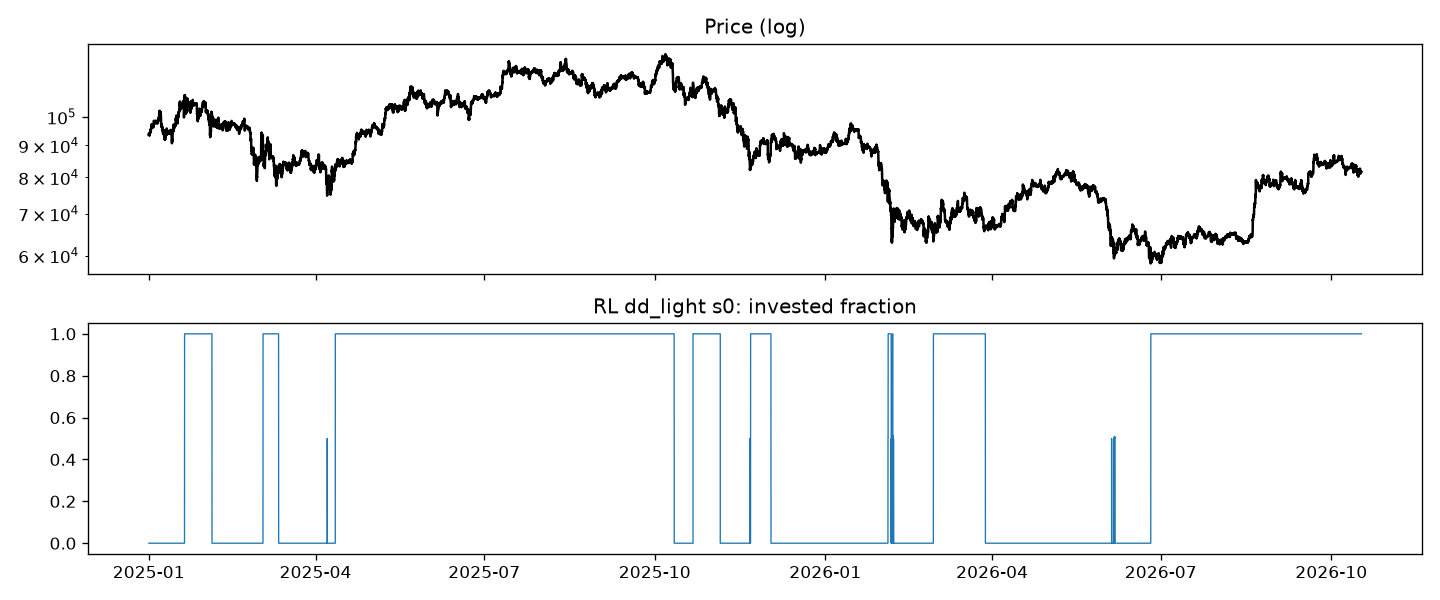

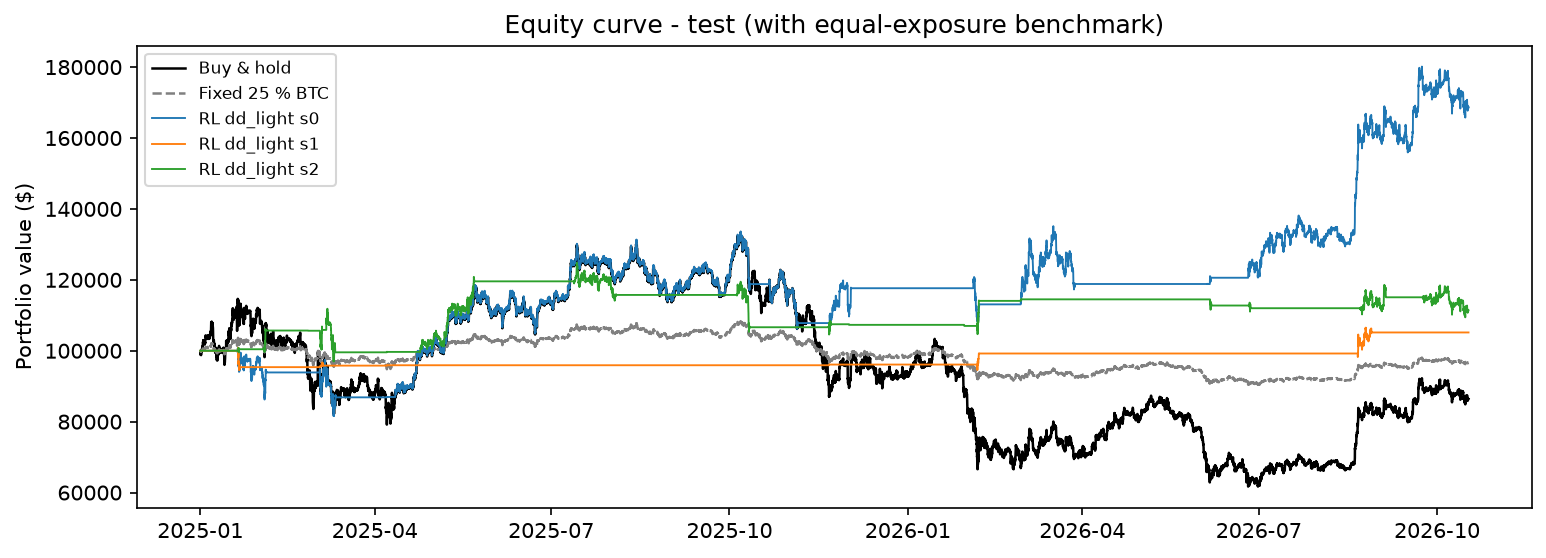

,cum_return_%,max_drawdown_%,sharpe,return_over_dd,costs_$,n_trades,avg_exposure_%
Buy & hold,-13.61,-53.74,0.03,-0.25,100.00,1.0,100.00
RL dd_light s0,68.72,-20.59,1.11,3.34,3046.63,45.0,57.49
RL dd_light ensemble,1.12,-14.14,0.12,0.08,1979.76,31.0,10.71
RL dd_light s1,5.16,-6.27,0.42,0.82,1265.67,21.0,1.35
RL dd_light s2,11.38,-16.21,0.44,0.70,3806.28,54.0,15.73
Random (mean of 20),-99.91,-99.91,-13.69,-1.00,102399.32,10466.9,50.08
RL dd_light (mean of seeds),28.42,-14.36,0.65,1.62,2706.19,40.0,24.85
Fixed 25 % BTC (descriptive),-3.40,-16.54,-0.12,-0.21,25.00,1.0,23.79


In [25]:
test_was_run = False
if not RUN_HELD_OUT_TEST:
    print('Test held-out omitido. Para ejecutarlo, cierra primero la decisión en validación y cambia RUN_HELD_OUT_TEST a True.')
else:
    cfg = load_config(CONFIG_PATH)
    subprocess.run([sys.executable, '-m', 'src.evaluate', '--config', CONFIG_PATH, '--split', 'test'], cwd=ROOT, check=True)
    test_was_run = True
    if cfg['final_reward'] == 'dd_light':
        subprocess.run([sys.executable, '-m', 'src.benchmark_25'], cwd=ROOT, check=True)
    else:
        print('Benchmark 25% omitido: src.benchmark_25.py usa actualmente dd_light y semillas 0, 1, 2 de forma fija.')

if test_was_run:
    metrics_test_path = RESULTS_DIR / 'metrics_test.csv'
    display(pd.read_csv(metrics_test_path, index_col=0))
    for image_name in ['equity_test.png', 'positions_test.png', 'equity_test_with_benchmark.png']:
        image_path = RESULTS_DIR / image_name
        if image_path.exists():
            display(__import__('IPython').display.Image(filename=str(image_path)))
    benchmark_metrics = RESULTS_DIR / 'metrics_test_with_benchmark.csv'
    if benchmark_metrics.exists():
        display(pd.read_csv(benchmark_metrics, index_col=0))

## 7. Resumen para el informe
La última celda genera un resumen Markdown en `results/resumen_informe.md`, incluyendo las tablas disponibles, el protocolo y los enlaces relativos a las figuras creadas.

In [31]:
from datetime import date


def markdown_table(frame):
    return frame.to_markdown()


def metric_text(row, key, suffix=''):
    return f"{float(row[key]):.2f}{suffix}"


cfg = load_config(CONFIG_PATH)
metrics_val_path = RESULTS_DIR / 'metrics_val.csv'
metrics_test_path = RESULTS_DIR / 'metrics_test.csv'
metrics_val = pd.read_csv(metrics_val_path, index_col=0) if metrics_val_path.exists() else pd.DataFrame()
metrics_test = pd.read_csv(metrics_test_path, index_col=0) if metrics_test_path.exists() else pd.DataFrame()
validation_agent_name = f"RL {cfg['final_reward']} (mean of seeds)"
test_agent_name = validation_agent_name
has_validation_results = validation_agent_name in metrics_val.index
has_test_results = test_agent_name in metrics_test.index
benchmark_path = RESULTS_DIR / 'metrics_test_with_benchmark.csv'
benchmark_metrics = pd.read_csv(benchmark_path, index_col=0) if benchmark_path.exists() else pd.DataFrame()

validation_interpretation = 'No se encontraron métricas agregadas de validación para la recompensa final.'
if has_validation_results:
    validation_agent = metrics_val.loc[validation_agent_name]
    validation_interpretation = (
        f"En validación, el promedio de semillas de `{cfg['final_reward']}` obtuvo "
        f"{metric_text(validation_agent, 'cum_return_%')}% de retorno acumulado, "
        f"drawdown máximo de {metric_text(validation_agent, 'max_drawdown_%')}%, "
        f"Sharpe de {metric_text(validation_agent, 'sharpe')} y exposición promedio de "
        f"{metric_text(validation_agent, 'avg_exposure_%')}%."
    )

seed_interpretation = ''
if has_test_results:
    test_agent = metrics_test.loc[test_agent_name]
    test_buy_hold = metrics_test.loc['Buy & hold'] if 'Buy & hold' in metrics_test.index else None
    test_interpretation = (
        f"En el período held-out, el promedio de semillas de `{cfg['final_reward']}` obtuvo "
        f"{metric_text(test_agent, 'cum_return_%')}% de retorno acumulado, drawdown máximo de "
        f"{metric_text(test_agent, 'max_drawdown_%')}%, Sharpe de {metric_text(test_agent, 'sharpe')}, "
        f"{metric_text(test_agent, 'n_trades')} operaciones y exposición promedio de "
        f"{metric_text(test_agent, 'avg_exposure_%')}%."
    )
    if test_buy_hold is not None:
        return_word = 'superó' if test_agent['cum_return_%'] > test_buy_hold['cum_return_%'] else 'no superó'
        risk_word = 'menor' if abs(test_agent['max_drawdown_%']) < abs(test_buy_hold['max_drawdown_%']) else 'mayor o igual'
        test_interpretation += (
            f" Frente a comprar y mantener, {return_word} el retorno acumulado "
            f"({metric_text(test_agent, 'cum_return_%')}% frente a {metric_text(test_buy_hold, 'cum_return_%')}%) "
            f"y presentó una magnitud de drawdown {risk_word} "
            f"({metric_text(test_agent, 'max_drawdown_%')}% frente a {metric_text(test_buy_hold, 'max_drawdown_%')}%)."
        )
    seed_rows = [name for name in metrics_test.index if name.startswith(f"RL {cfg['final_reward']} s")]
    if seed_rows:
        seed_returns = metrics_test.loc[seed_rows, 'cum_return_%']
        seed_interpretation = (
            f"La sensibilidad a la semilla es relevante: el retorno individual de las semillas "
            f"varió entre {seed_returns.min():.2f}% y {seed_returns.max():.2f}%."
        )

features_description = (
    '`ret_1` (retorno logarítmico horario), `ret_short` (momentum de 24 horas), '
    '`ma_gap` (distancia a la media móvil de 168 horas), `volatility` (volatilidad de 24 horas), '
    '`rsi` (RSI de 14 períodos reescalado) y la posición actual.'
)
reward_params = cfg['rewards'][cfg['final_reward']]
dd_penalty = reward_params.get('dd_penalty', 0.0)
turnover_penalty = reward_params.get('turnover_penalty', 0.0)
reward_formula = (
    f"100 × [log(Vₜ₊₁/Vₜ) - {dd_penalty:g} × ΔDDₜ⁺ "
    f"- {turnover_penalty:g} × |wₜ - wₜ₋₁|]"
)
reward_rows = [
    {'Recompensa': name,
     'Penalización drawdown': params.get('dd_penalty', 0.0),
     'Penalización turnover': params.get('turnover_penalty', 0.0)}
    for name, params in cfg['rewards'].items()
]
reward_table = pd.DataFrame(reward_rows).to_markdown(index=False)

dqn = cfg['dqn']
env = cfg['env']
hyperparameter_rows = [
    {'Parámetro': 'Arquitectura MLP', 'Valor': ' → '.join(map(str, dqn['net_arch']))},
    {'Parámetro': 'Learning rate', 'Valor': dqn['learning_rate']},
    {'Parámetro': 'Batch size', 'Valor': dqn['batch_size']},
    {'Parámetro': 'Factor de descuento γ', 'Valor': dqn['gamma']},
    {'Parámetro': 'Replay buffer', 'Valor': dqn['buffer_size']},
    {'Parámetro': 'Pasos máximos', 'Valor': dqn['total_timesteps']},
    {'Parámetro': 'Evaluación / paciencia', 'Valor': f"cada {dqn['eval_freq']} pasos / {dqn['patience']} evaluaciones"},
    {'Parámetro': 'Longitud de episodio', 'Valor': f"{env['episode_length']} horas"},
    {'Parámetro': 'Semillas', 'Valor': ', '.join(map(str, cfg['seeds']))},
]
hyperparameter_table = pd.DataFrame(hyperparameter_rows).to_markdown(index=False)

figure_lines = []
figures = [
    ('Análisis exploratorio (train + validación)', 'eda_informe.png'),
    ('Curvas de entrenamiento', 'curvas_entrenamiento.png'),
    ('Curvas de capital en validación', 'equity_val.png'),
    ('Posiciones del agente en validación', 'positions_val.png'),
    ('Curvas de capital en test held-out', 'equity_test.png'),
    ('Posiciones del agente en test held-out', 'positions_test.png'),
    ('Comparación con benchmark de exposición fija', 'equity_test_with_benchmark.png'),
]
for caption, filename in figures:
    if (RESULTS_DIR / filename).exists():
        figure_lines.extend([f'### {caption}', '', f'![{caption}]({filename})', ''])

validation_table = markdown_table(metrics_val) if not metrics_val.empty else 'No disponible: primero ejecuta la evaluación de validación.'
test_table = markdown_table(metrics_test) if has_test_results else 'No disponible para la recompensa final configurada. El test solo debe ejecutarse después de cerrar la selección con validación.'
benchmark_table = markdown_table(benchmark_metrics) if not benchmark_metrics.empty else 'No disponible.'
report_sections = [
    '# Bitcoin Sabana Agent RL: evaluación de una estrategia DQN para BTC/USDT',
    '',
    '**Informe Final**  ',
    '',
    '## Resumen',
    f"Este trabajo desarrolla y evalúa un agente de aprendizaje por refuerzo profundo basado en Deep Q-Network (DQN) para decidir la exposición a Bitcoin en un portafolio simulado. Se utilizaron velas horarias de BTC/USDT, cuatro funciones de recompensa y tres semillas aleatorias. La selección del modelo se realizó con validación temporal y el conjunto de test se reservó para una evaluación final. {validation_interpretation} {test_interpretation}",
    '',
    '**Palabras clave:** aprendizaje por refuerzo, DQN, Bitcoin, gestión de portafolio, drawdown, costos de transacción.',
    '',
    '## 1. Introducción',
    'La volatilidad de los criptoactivos hace que una estrategia de inversión deba considerar conjuntamente el retorno, el riesgo de pérdidas y los costos de operación. Comprar y mantener constituye una referencia sencilla, pero mantiene exposición completa durante todo el período. El aprendizaje por refuerzo ofrece una alternativa: un agente observa información de mercado y una posición vigente, y aprende una política de acciones a partir de recompensas definidas sobre la evolución del portafolio.',
    'Este proyecto estudia si un DQN pequeño puede aprender una política de exposición larga a BTC/USDT que resulte útil fuera de muestra. El diseño compara distintas formulaciones de recompensa y controla el uso temporal de los datos para separar el entrenamiento, la selección y la evaluación final.',
    '',
    '## 2. Problema y pregunta de investigación',
    '**Problema:** una estrategia basada solo en crecimiento puede operar en exceso o exponerse a caídas pronunciadas; penalizaciones de riesgo mal calibradas también pueden inducir al agente a permanecer en efectivo.',
    '**Pregunta de investigación:** ¿puede un agente DQN entrenado con datos históricos aprender una política de exposición a BTC que ofrezca un balance razonable entre retorno, drawdown y costos al evaluarse en un período temporal no visto?',
    '',
    '## 3. Objetivos',
    '### Objetivo general',
    'Diseñar y evaluar un agente DQN para asignar exposición a BTC/USDT, comparando su desempeño y riesgo con estrategias de referencia en períodos de validación y test temporalmente separados.',
    '### Objetivos específicos',
    '- Construir variables de estado retrospectivas y normalizarlas exclusivamente con estadísticas del período de entrenamiento.',
    '- Implementar un entorno de inversión con acciones discretas, capital inicial y costos de transacción explícitos.',
    '- Comparar cuatro funciones de recompensa mediante tres semillas, seleccionando la configuración únicamente con validación.',
    '- Medir retorno acumulado, drawdown máximo, Sharpe, costos, número de operaciones y exposición promedio frente a comprar y mantener y un agente aleatorio.',
    '- Documentar las limitaciones de generalización y sensibilidad a las semillas.',
    '',
    '## 4. Justificación y alcance',
    'El experimento permite estudiar de forma reproducible los compromisos entre rentabilidad, riesgo y rotación en una serie financiera horaria. El alcance se limita a BTC/USDT, posiciones largas sin apalancamiento y tres niveles de inversión. Los resultados son evidencia experimental para el período disponible; no constituyen asesoría financiera ni garantizan desempeño futuro.',
    '',
    '## 5. Marco conceptual',
    'El aprendizaje por refuerzo modela la interacción entre un agente, un estado, una acción y una recompensa acumulada. DQN aproxima los valores de acción mediante una red neuronal y emplea replay buffer y red objetivo para estabilizar el aprendizaje. En este proyecto, la recompensa combina el retorno logarítmico del portafolio con penalizaciones por profundización del drawdown y cambios de exposición. El Sharpe y el drawdown se reportan como métricas complementarias, no como objetivos optimizados directamente en todos los experimentos.',
    '',
    '## 6. Metodología',
    '### 6.1 Datos y partición temporal',
    f"Los datos corresponden a velas de una hora de BTC/USDT, obtenidas de Binance mediante el descargador `gym-trading-env`. El archivo utilizado es `{cfg['data']['path']}`. Las fechas y cantidades efectivas por partición son:",
    split_table.to_markdown(),
    'El período de entrenamiento ajusta el agente y los parámetros de normalización; validación sirve para comparar recompensas y seleccionar checkpoints. Test queda reservado para evaluación final. Las variables se calculan con datos presentes y pasados, y el notebook ejecuta un chequeo automático de lookahead.',
    '### 6.2 Estado, acciones y entorno',
    f"El estado contiene seis componentes: {features_description} Las acciones corresponden a exposiciones {', '.join(f'{100 * weight:.0f}%' for weight in env['positions'])} del capital, con posiciones largas y sin apalancamiento. El capital inicial es ${env['initial_value']:,.0f}; la comisión es {env['fee'] * 10000:.0f} puntos básicos sobre el nominal operado.",
    '### 6.3 Recompensas',
    'Se compararon las siguientes penalizaciones, aplicadas a la recompensa base de retorno logarítmico neto de costos:',
    reward_table,
    f"Para la configuración final `{cfg['final_reward']}`, la forma general empleada es:",
    f"$$r_t = {reward_formula}$$",
    '### 6.4 Entrenamiento y reproducibilidad',
    f"Se entrenó un DQN con arquitectura MLP de dos capas ocultas, early stopping por recompensa de validación y semillas {', '.join(map(str, cfg['seeds']))}. Los principales hiperparámetros configurados son:",
    hyperparameter_table,
    'Los checkpoints se seleccionan con validación. El resultado principal por recompensa es el promedio de semillas; el test no interviene en el entrenamiento, la selección de recompensa ni el ajuste de hiperparámetros.',
    '### 6.5 Métricas y comparadores',
    'La evaluación informa retorno acumulado, drawdown máximo, Sharpe anualizado para datos horarios, costos acumulados, número de operaciones y exposición promedio. Los comparadores son comprar y mantener y el promedio de 20 ejecuciones de una política aleatoria. El benchmark de 25% fijo en BTC es descriptivo y no participa en la selección.',
    '',
    '## 7. Resultados',
    '### 7.1 Validación',
    validation_interpretation,
    validation_table,
    '### 7.2 Test held-out',
    test_interpretation,
    test_table,
    '### 7.3 Benchmark descriptivo',
    benchmark_table,
    '### 7.4 Figuras',
    *figure_lines,
    '',
    '## 8. Discusión',
    f"{validation_interpretation} {test_interpretation}",
    seed_interpretation if seed_interpretation else 'La sensibilidad entre semillas debe examinarse con las métricas individuales antes de generalizar el resultado promedio.',
    'La comparación debe interpretarse considerando que los regímenes de mercado pueden diferir entre validación y test, y que el promedio de pocas semillas puede ocultar variabilidad importante. El benchmark de exposición fija aporta contexto sobre el efecto de invertir parcialmente, pero no sustituye una evaluación con más períodos y activos.',
    '',
    '## 9. Conclusiones',
    f"1. El proyecto implementa un flujo reproducible de DQN para asignación discreta de exposición a BTC y explicita costos, selección temporal y métricas de riesgo. {validation_interpretation}",
    f"2. {test_interpretation}",
    f"3. Estos resultados responden la pregunta de investigación de forma condicionada al activo, período, costos y semillas evaluados; {seed_interpretation.lower() if seed_interpretation else 'se requiere ampliar la evaluación para valorar la estabilidad estadística.'}",
    '4. En consecuencia, el agente debe considerarse un prototipo experimental y no una recomendación de inversión.',
    '',
    '## 10. Limitaciones y trabajo futuro',
    '- La evaluación se limita a un activo y un único período held-out; no permite inferir robustez en otros regímenes o mercados.',
    '- Tres semillas ofrecen una caracterización inicial, pero no bastan para establecer significancia estadística; conviene reportar intervalos de confianza y ampliar las semillas.',
    '- El backtest no modela todos los elementos de ejecución real, como deslizamiento, latencia, liquidez variable, impuestos o restricciones operativas.',
    '- Como trabajo futuro se propone evaluar ventanas walk-forward, más activos y períodos, costos y deslizamientos alternativos, y pruebas de sensibilidad de hiperparámetros definidas sin consultar test.',
    '',
    '## 11. Reproducibilidad y archivos',
    f"La configuración está en `configs/default.yaml`; los módulos de datos, entorno, agente, entrenamiento y evaluación están en `src/`. La ejecución se realizó con los artefactos que actualmente existen en `models/` y `results/`. Fecha de generación del informe: {date.today().isoformat()}.",
    '',
    '## Referencias',
    'Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature, 518*, 529–533. https://doi.org/10.1038/nature14236',
    'Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2.ª ed.). MIT Press.',
    'Binance. Datos históricos de mercado BTC/USDT en velas de una hora; descargados según la configuración del proyecto.',
    '',
    '---'
]
report_path = RESULTS_DIR / 'resumen_informe.md'
report_path.write_text('\n'.join(str(section) for section in report_sections) + '\n', encoding='utf-8')
print(f'Informe guardado en: {report_path.relative_to(ROOT)}')
print(report_path.read_text(encoding='utf-8'))

Informe guardado en: results\resumen_informe.md
# Bitcoin Sabana Agent RL: evaluación de una estrategia DQN para BTC/USDT

**Informe Final**  

## Resumen
Este trabajo desarrolla y evalúa un agente de aprendizaje por refuerzo profundo basado en Deep Q-Network (DQN) para decidir la exposición a Bitcoin en un portafolio simulado. Se utilizaron velas horarias de BTC/USDT, cuatro funciones de recompensa y tres semillas aleatorias. La selección del modelo se realizó con validación temporal y el conjunto de test se reservó para una evaluación final. En validación, el promedio de semillas de `dd_light` obtuvo 74.51% de retorno acumulado, drawdown máximo de -11.11%, Sharpe de 2.14 y exposición promedio de 23.87%. En el período held-out, el promedio de semillas de `dd_light` obtuvo 28.42% de retorno acumulado, drawdown máximo de -14.36%, Sharpe de 0.65, 40.00 operaciones y exposición promedio de 24.85%. Frente a comprar y mantener, superó el retorno acumulado (28.42% frente a -13.61%) y present